In [73]:
import matplotlib.pyplot as plt
from collections import deque
import heapq
import math

# Mapa zapisana tekstowo: "." – pole dostępne (0), "#" – przeszkoda (1), "/" - piasek (3), "~" - bagno (5)
MAP = [
    "...#...#...#..",
    ".....#....#...",
    ".....###.../~~",
    "....///#~~~...",
    "...#..##.#....",
    "..////...#...#",
    "#.#...#~~.///#",
    "....~~##.....#",
    "..~#.~..//####",
    ".....#~~~.....",
]

grid = [[1 if ch == "#"

         else 0 for ch in wiersz] for wiersz in MAP]

start = (0, 0)
goal = (9, 13)

rows = len(grid)
cols = len(grid[0])

print("Rozmiar planszy:", rows, "x", cols)
print("Start:", start)
print("Cel:", goal)

Rozmiar planszy: 10 x 14
Start: (0, 0)
Cel: (9, 13)


In [74]:
def get_neighbors(state):
    r, c = state

    moves = [
        (-1, 0),  # góra
        (1,  0),  # dół
        (0, -1),  # lewo
        (0,  1)   # prawo
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols and grid[nr][nc] == 0:
            neighbors.append((nr, nc))

    return neighbors
print("Sąsiedzi startu:", get_neighbors(start))

Sąsiedzi startu: [(1, 0), (0, 1)]


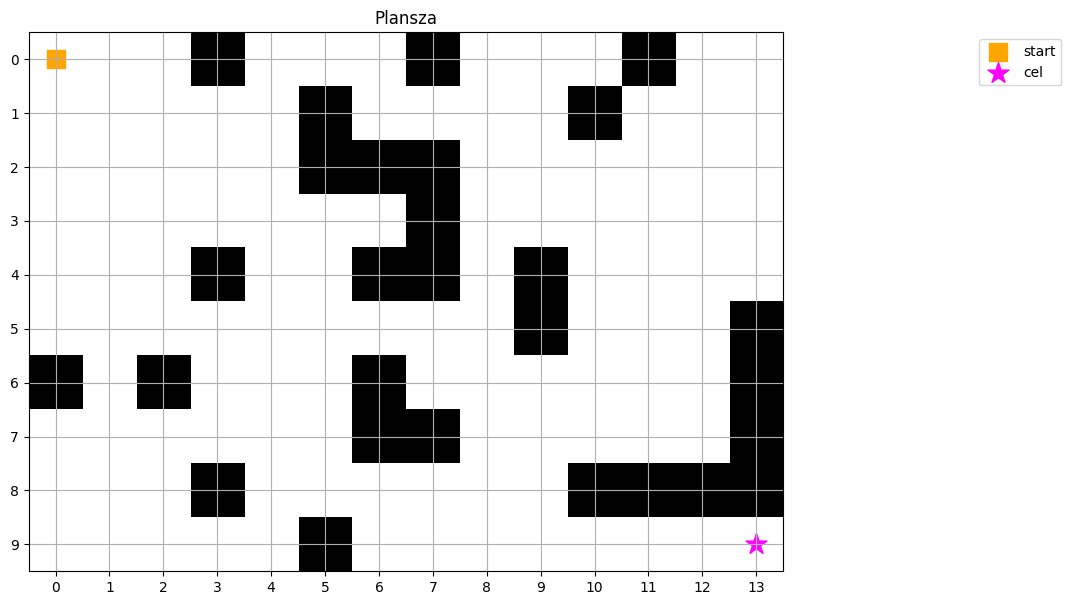

In [75]:
def draw_grid(path=None, visited=None, title="Plansza"):
    img = [[1 if cell == 0 else 0 for cell in row] for row in grid]

    plt.figure(figsize=(10, 7))
    plt.imshow(img, cmap="gray", origin="upper")

    if visited:
        vr = [p[0] for p in visited]
        vc = [p[1] for p in visited]
        # kolor punktu = kolejność odwiedzin (ciemny – wcześnie, jasny – późno)
        sc = plt.scatter(vc, vr, c=range(len(visited)), cmap="viridis",
                         s=110, alpha=0.85, label="odwiedzone")
        plt.colorbar(sc, label="kolejność odwiedzin", shrink=0.8)

    if path:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]
        plt.plot(pc, pr, color="red", marker="o", linewidth=3, label="ścieżka")

    plt.scatter(start[1], start[0], s=180, marker="s", color="orange", label="start")
    plt.scatter(goal[1], goal[0], s=250, marker="*", color="magenta", label="cel")

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.grid(True)
    plt.title(title)
    plt.legend(loc="upper left", bbox_to_anchor=(1.25, 1))
    plt.show()


draw_grid()

BFS - długość ścieżki: 22
BFS - odwiedzone stany: 112
BFS - ścieżka: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (5, 1), (6, 1), (7, 1), (7, 2), (7, 3), (7, 4), (8, 4), (8, 5), (8, 6), (9, 6), (9, 7), (9, 8), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


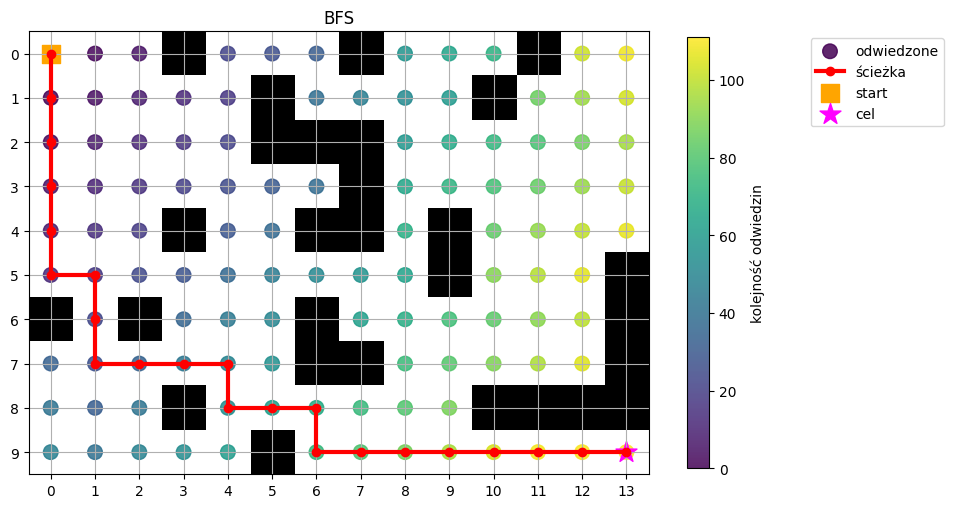

In [76]:

def reconstruct_path(parent, goal):
    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path


def bfs(start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    visit_order = []

    while queue:
        current = queue.popleft()
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, visit_order


bfs_path, bfs_visited = bfs(start, goal)

print("BFS - długość ścieżki:", len(bfs_path) - 1)
print("BFS - odwiedzone stany:", len(bfs_visited))
print("BFS - ścieżka:", bfs_path)

draw_grid(bfs_path, bfs_visited, "BFS")


DFS - długość ścieżki: 40
DFS - odwiedzone stany: 42
DFS - ścieżka: [(0, 0), (0, 1), (0, 2), (1, 2), (1, 3), (1, 4), (2, 4), (2, 3), (2, 2), (2, 1), (2, 0), (3, 0), (3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (4, 5), (4, 4), (5, 4), (5, 5), (5, 6), (5, 7), (5, 8), (6, 8), (6, 9), (6, 10), (6, 11), (6, 12), (7, 12), (7, 11), (7, 10), (7, 9), (7, 8), (8, 8), (8, 9), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


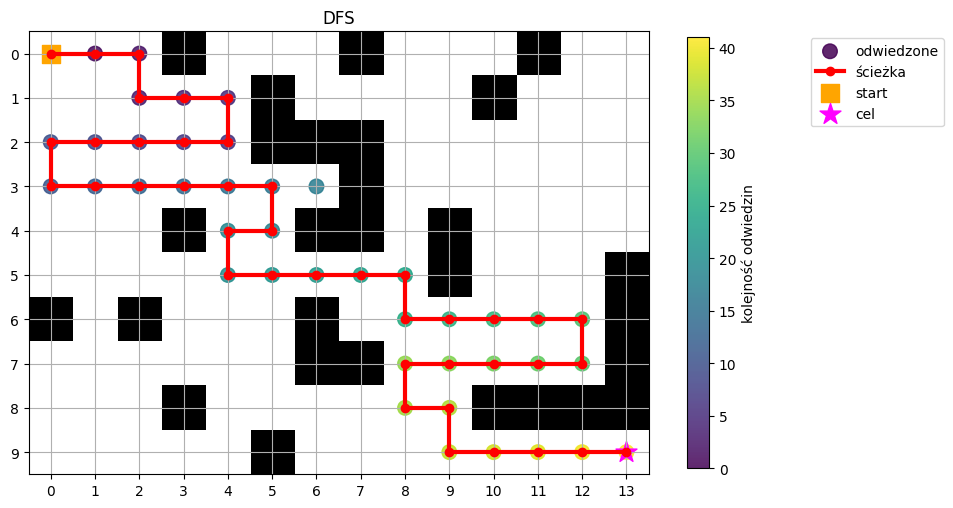

In [77]:
def dfs(start, goal):
    # Na stosie trzymamy pary (stan, rodzic). Rodzica zapisujemy dopiero wtedy,
    # gdy DFS faktycznie wchodzi do stanu – dzięki temu narysowana ścieżka
    # jest drogą, którą algorytm naprawdę przeszedł.
    stack = [(start, None)]
    visited = set()
    parent = {}
    visit_order = []

    while stack:
        current, current_parent = stack.pop()

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                stack.append((neighbor, current))

    return None, visit_order


dfs_path, dfs_visited = dfs(start, goal)

print("DFS - długość ścieżki:", len(dfs_path) - 1)
print("DFS - odwiedzone stany:", len(dfs_visited))
print("DFS - ścieżka:", dfs_path)

draw_grid(dfs_path, dfs_visited, "DFS")

In [78]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def euclidean(a, b):
    return math.sqrt((a[0] - b[0])**2 + (a[1] - b[1])**2)

def chebyshev(a, b):
    return max(abs(a[0] - b[0]), abs(a[1] - b[1]))


examples = [(0, 0), (4, 6), (7, 10), (9, 12)]

for state in examples:
    print(
        state,
        "Manhattan =", round(manhattan(state, goal), 2),
        "Euclidean =", round(euclidean(state, goal), 2),
        "Chebyshev =", round(chebyshev(state, goal), 2)
    )

(0, 0) Manhattan = 22 Euclidean = 15.81 Chebyshev = 13
(4, 6) Manhattan = 12 Euclidean = 8.6 Chebyshev = 7
(7, 10) Manhattan = 5 Euclidean = 3.61 Chebyshev = 3
(9, 12) Manhattan = 1 Euclidean = 1.0 Chebyshev = 1


A* - koszt: 22
A* - odwiedzone stany: 74
A* - ścieżka: [(0, 0), (0, 1), (0, 2), (1, 2), (1, 3), (1, 4), (2, 4), (3, 4), (3, 5), (4, 5), (5, 5), (5, 6), (5, 7), (5, 8), (6, 8), (6, 9), (7, 9), (8, 9), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


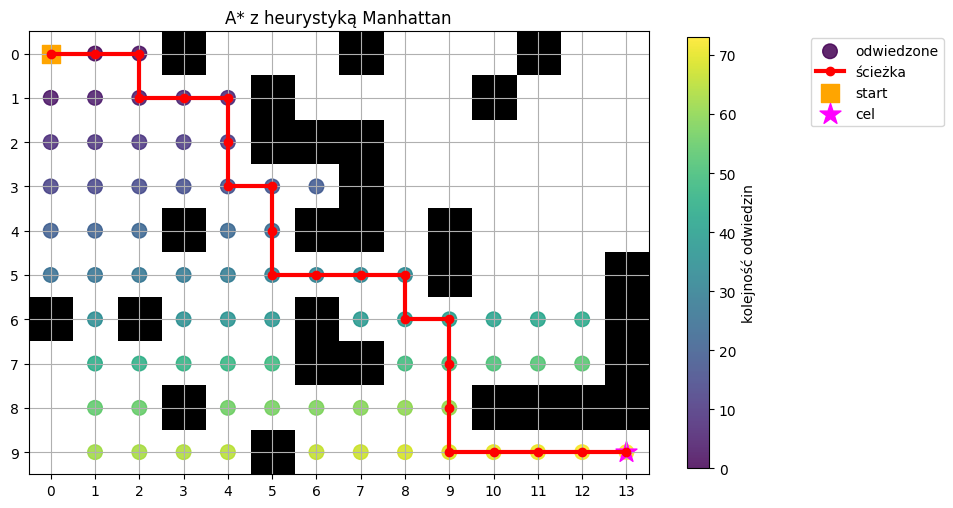

In [79]:
def astar(start, goal, heuristic=manhattan):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            tentative_g = g_score[current] + 1

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")


astar_path, astar_visited, astar_cost = astar(start, goal)

print("A* - koszt:", astar_cost)
print("A* - odwiedzone stany:", len(astar_visited))
print("A* - ścieżka:", astar_path)

draw_grid(astar_path, astar_visited, "A* z heurystyką Manhattan")

ZD. 4 tworzenie ruchu po przekatnej

Manhattan nie jest dopuszczalna w przypadku ruchu po przekatnej i nie jest najlepszym wyborem, pokaze na przykladzie:

> manhattan = h(n)

np nasz start w (0,0), cel w (4,4).
W standartowej funkcji get_neighbors h(n) = |0-4| + |0-4| co daje h(n) = 8, i co jest najmniejszym kosztem, a w przypadku get_neighbors_diagonale realny koszt jest rowny 4, czyli 8>4 (h>h*), co pokazuje ta niedopuszczalnosc. Przez to najlepszym wyborem jest Chebyshev

W przypadku gdy ruch po przekatnej rowna sie pierwiastkowi z dwoch, koszt w A* rowna sie √2,
bfs staje sie nieefektywnym, i najlepsza heurystyka jest octile

In [80]:
def get_neighbors_diagonale(state):
    r, c = state
    moves = [
        (-1, 0),
        (1,  0),
        (0, -1),
        (0,  1),
        (-1,-1),
        (-1, 1),
        (1, -1),
        (1,  1)
        ]
    result = []
    for dr, dc in moves:
        nr, nc = r + dr, c + dc
        if 0 <= nr < rows and 0 <= nc < cols and grid[nr][nc] == 0:
            cost = math.sqrt(2) if (dr != 0 and dc != 0) else 1
            result.append(((nr, nc), cost))          # zwracamy (sąsiad, koszt ruchu)
    return result

In [81]:
def octile(a, b):
    dr, dc = abs(a[0] - b[0]), abs(a[1] - b[1])
    return math.sqrt(2) * min(dr, dc) + (max(dr, dc) - min(dr, dc))

Manhattan  koszt=16.728  kroki=13  odwiedzone=14


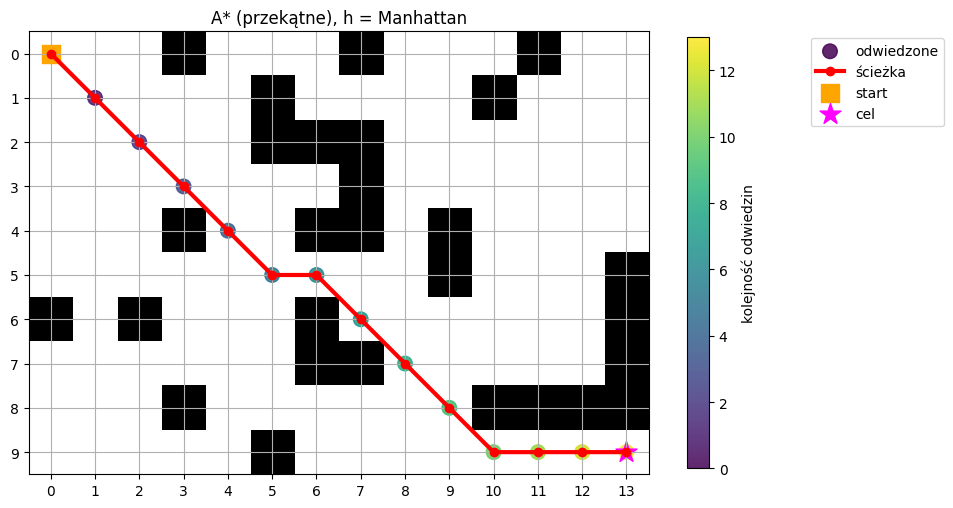

Chebyshev  koszt=16.728  kroki=13  odwiedzone=54


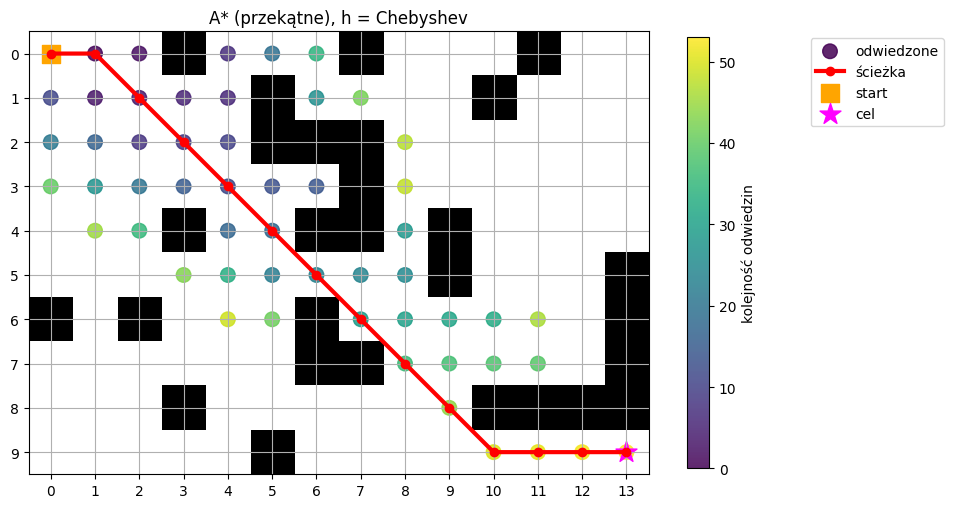

Octile     koszt=16.728  kroki=13  odwiedzone=33


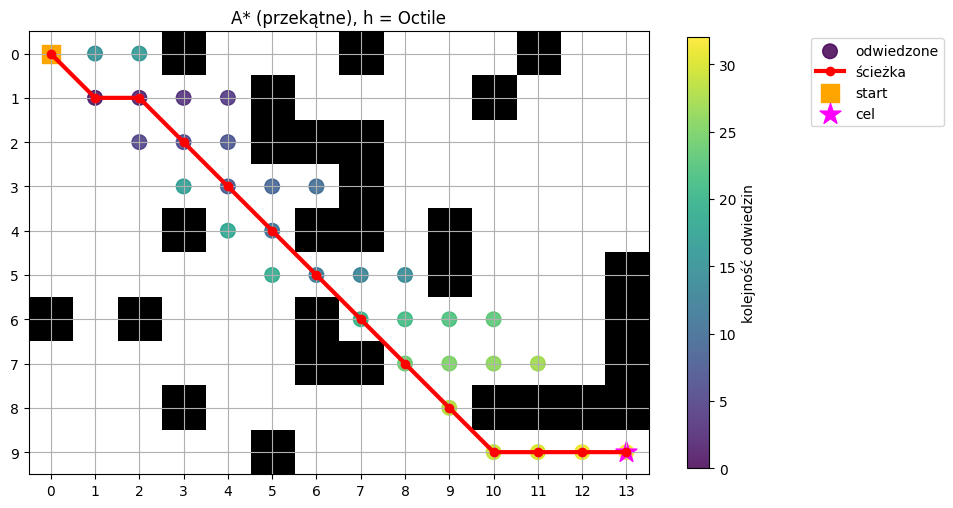

In [82]:
def astar_general(start, goal, neighbors_fn, heuristic):
    open_heap = [(heuristic(start, goal), start)]
    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    order = []

    while open_heap:
        _, cur = heapq.heappop(open_heap)
        if cur in closed:
            continue
        closed.add(cur)
        order.append(cur)

        if cur == goal:
            return reconstruct_path(parent, goal), order, g_score[goal]

        for nb, cost in neighbors_fn(cur):           # <- koszt przychodzi z funkcji
            if nb in closed:
                continue
            new_g = g_score[cur] + cost              # <- zamiast "+ 1"
            if new_g < g_score.get(nb, float("inf")):
                g_score[nb] = new_g
                parent[nb] = cur
                heapq.heappush(open_heap, (new_g + heuristic(nb, goal), nb))

    return None, order, float("inf")


for name, h in [("Manhattan", manhattan), ("Chebyshev", chebyshev), ("Octile", octile)]:
    p, o, c = astar_general(start, goal, get_neighbors_diagonale, h)
    print(f"{name:<10} koszt={c:.3f}  kroki={len(p)-1}  odwiedzone={len(o)}")
    draw_grid(p, o, f"A* (przekątne), h = {name}")

ZD. 5

BFS juz nie jest najtanszym, poniewaz BFS w ogole nie przyznaczony na mniejszy koszt, a na minimalna ilosc krokow

In [83]:
cost_grid = [[None if ch == "#" else 3 if ch == "/" else 5 if ch == "~" else 1
              for ch in row] for row in MAP]

def get_neighbors_terrain(state):
    r, c = state
    result = []
    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nr, nc = r + dr, c + dc
        if 0 <= nr < rows and 0 <= nc < cols and cost_grid[nr][nc] is not None:
            result.append(((nr, nc), cost_grid[nr][nc]))   # koszt pola, gdzie wchodzimy
    return result


def path_cost(path):
    return sum(cost_grid[r][c] for (r, c) in path[1:])


bfs_p, bfs_o = bfs(start, goal)
a_p, a_o, a_c = astar_general(start, goal, get_neighbors_terrain, manhattan)

print("BFS: kroki", len(bfs_p) - 1, "| koszt", path_cost(bfs_p))
print("A* : kroki", len(a_p) - 1, "| koszt", a_c)

BFS: kroki 22 | koszt 42
A* : kroki 22 | koszt 32


ZD. 6

g(n) jest kosztem ktory przeszlismy od startu do aktualnego stanu

h(n) szacowany koszt ktory zostal od aktualnego stanu do celu